In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# Loading the cleaned delivery data
project_path = os.path.dirname(os.getcwd())
data_path = os.path.join(project_path, "data")

df = pd.read_csv(os.path.join(data_path, "deliveries_clean.csv"))

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (295732, 23)


C:\Users\sw\AppData\Local\Temp\ipykernel_13212\4099710330.py:10: DtypeWarning: Columns (0: season) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(os.path.join(data_path, "deliveries_clean.csv"))


,match_id,innings,over,delivery_number,batting_team,batter,bowler,runs_batter,runs_total,wides,...,penalty,is_legal_delivery,bowler_runs,balls_faced,total_wickets,bowler_wickets,date,season,venue,city
0,1082591,1,0,1,Sunrisers Hyderabad,DA Warner,TS Mills,0,0,0,...,0,1,0,1,0,0,2017-04-05,2017,"Rajiv Gandhi International Stadium, Uppal",Hyderabad
1,1082591,1,0,2,Sunrisers Hyderabad,DA Warner,TS Mills,0,0,0,...,0,1,0,1,0,0,2017-04-05,2017,"Rajiv Gandhi International Stadium, Uppal",Hyderabad
2,1082591,1,0,3,Sunrisers Hyderabad,DA Warner,TS Mills,4,4,0,...,0,1,4,1,0,0,2017-04-05,2017,"Rajiv Gandhi International Stadium, Uppal",Hyderabad
3,1082591,1,0,4,Sunrisers Hyderabad,DA Warner,TS Mills,0,0,0,...,0,1,0,1,0,0,2017-04-05,2017,"Rajiv Gandhi International Stadium, Uppal",Hyderabad
4,1082591,1,0,5,Sunrisers Hyderabad,DA Warner,TS Mills,0,2,2,...,0,0,2,0,0,0,2017-04-05,2017,"Rajiv Gandhi International Stadium, Uppal",Hyderabad


In [2]:
# Dividing each innings into three bowling phases
def get_match_phase(over):
    if 0 <= over <= 5:
        return "Powerplay"
    elif 6 <= over <= 14:
        return "Middle Overs"
    elif 15 <= over <= 19:
        return "Death Overs"
    return "Other"

df["match_phase"] = df["over"].apply(get_match_phase)

df[["over", "match_phase"]].drop_duplicates().sort_values("over")

,over,match_phase
0,0,Powerplay
7,1,Powerplay
14,2,Powerplay
20,3,Powerplay
26,4,Powerplay
32,5,Powerplay
38,6,Middle Overs
44,7,Middle Overs
50,8,Middle Overs
56,9,Middle Overs


In [3]:
# Comparing runs, wickets and legal deliveries across phases
phase_stats = df[df["match_phase"] != "Other"].groupby(
    "match_phase"
).agg(
    total_runs=("runs_total", "sum"),
    total_wickets=("total_wickets", "sum"),
    legal_balls=("is_legal_delivery", "sum"),
    matches=("match_id", "nunique")
).reindex(
    ["Powerplay", "Middle Overs", "Death Overs"]
).reset_index()

phase_stats["run_rate"] = (
    phase_stats["total_runs"] /
    (phase_stats["legal_balls"] / 6).replace(0, np.nan)
).round(2)

phase_stats

,match_phase,total_runs,total_wickets,legal_balls,matches,run_rate
0,Powerplay,120503,3614,89318,1243,8.09
1,Middle Overs,174283,5708,131526,1241,7.95
2,Death Overs,106952,5383,63786,1226,10.06


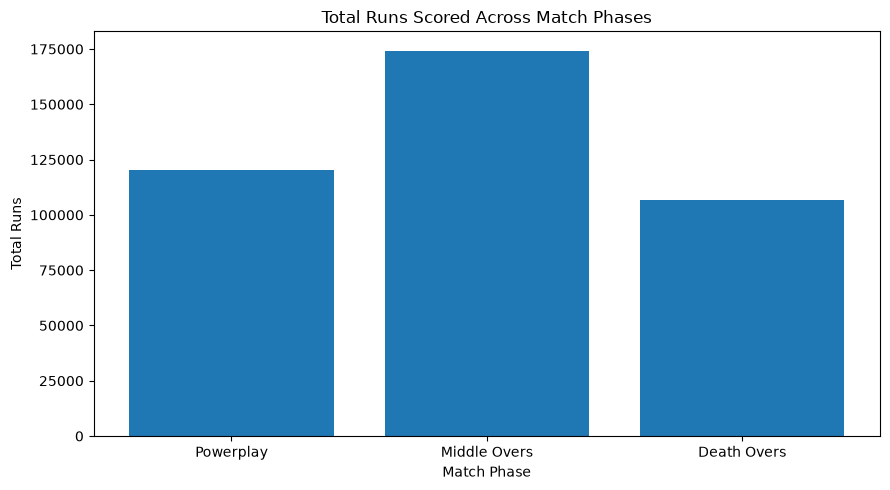

In [4]:
plt.figure(figsize=(9, 5))

plt.bar(
    phase_stats["match_phase"],
    phase_stats["total_runs"]
)

plt.title("Total Runs Scored Across Match Phases")
plt.xlabel("Match Phase")
plt.ylabel("Total Runs")

plt.tight_layout()
plt.show()

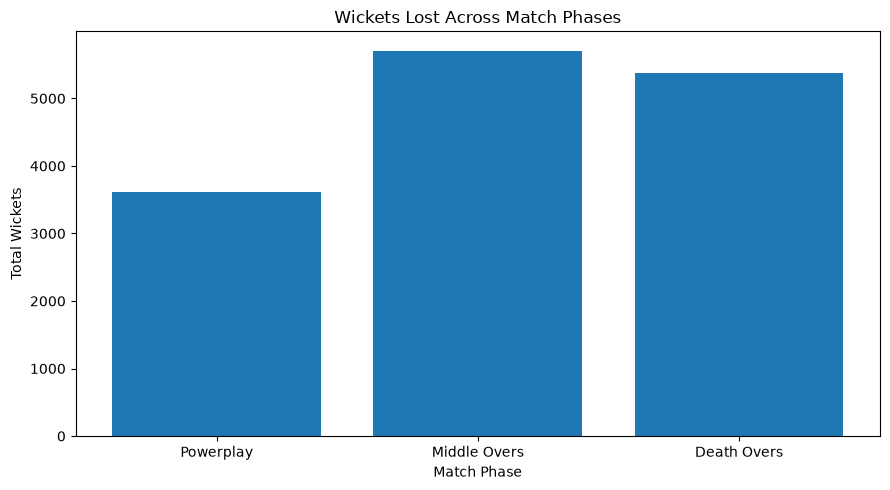

In [5]:
plt.figure(figsize=(9, 5))

plt.bar(
    phase_stats["match_phase"],
    phase_stats["total_wickets"]
)

plt.title("Wickets Lost Across Match Phases")
plt.xlabel("Match Phase")
plt.ylabel("Total Wickets")

plt.tight_layout()
plt.show()

In [7]:
# Comparing how individual teams score in each phase
team_phase_stats = df[df["match_phase"] != "Other"].groupby(
    ["batting_team", "match_phase"]
).agg(
    total_runs=("runs_total", "sum"),
    legal_balls=("is_legal_delivery", "sum"),
    wickets=("total_wickets", "sum")
).reset_index()

team_phase_stats["run_rate"] = (
    team_phase_stats["total_runs"] /
    (team_phase_stats["legal_balls"] / 6).replace(0, np.nan)
).round(2)

team_phase_stats.head(15)

,batting_team,match_phase,total_runs,legal_balls,wickets,run_rate
0,Chennai Super Kings,Death Overs,12392,7145,496,10.41
1,Chennai Super Kings,Middle Overs,18646,14208,570,7.87
2,Chennai Super Kings,Powerplay,12562,9545,358,7.90
3,Deccan Chargers,Death Overs,3133,2032,198,9.25
4,Deccan Chargers,Middle Overs,4913,4020,177,7.33
5,Deccan Chargers,Powerplay,3417,2700,109,7.59
6,Delhi Capitals,Death Overs,5230,3108,263,10.10
7,Delhi Capitals,Middle Overs,8543,6362,281,8.06
8,Delhi Capitals,Powerplay,6186,4302,201,8.63
9,Delhi Daredevils,Death Overs,6272,3902,312,9.64


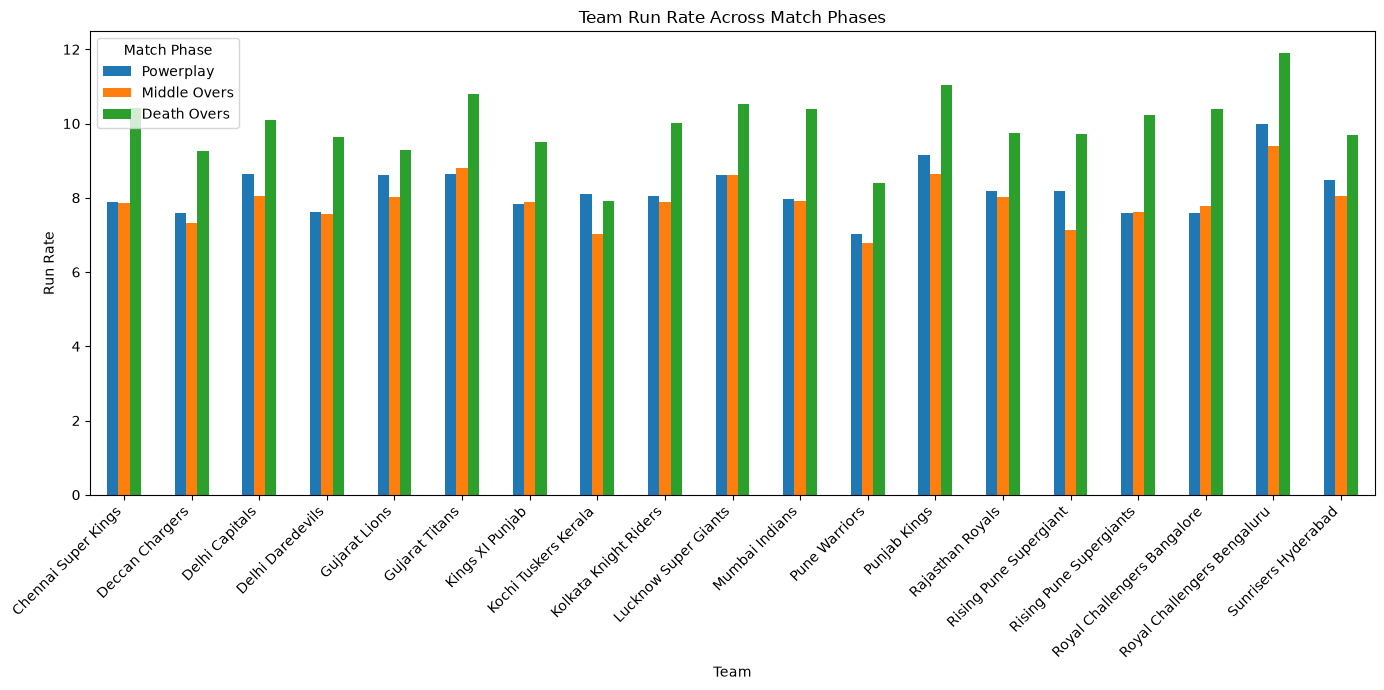

In [8]:
# Comparing team scoring rates across all three phases
team_phase_pivot = team_phase_stats.pivot(
    index="batting_team",
    columns="match_phase",
    values="run_rate"
)

team_phase_pivot = team_phase_pivot[
    ["Powerplay", "Middle Overs", "Death Overs"]
]

team_phase_pivot.plot(
    kind="bar",
    figsize=(14, 7)
)

plt.title("Team Run Rate Across Match Phases")
plt.xlabel("Team")
plt.ylabel("Run Rate")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Match Phase")

plt.tight_layout()
plt.show()

In [9]:
# Saving phase statistics for future use
phase_stats.to_csv(
    os.path.join(data_path, "phase_stats.csv"),
    index=False
)

team_phase_stats.to_csv(
    os.path.join(data_path, "team_phase_stats.csv"),
    index=False
)

print("Match phase datasets saved successfully!")

Match phase datasets saved successfully!
